# 11. Is there hidden structure in the data?

> **In plain terms.** We looked for hidden groups of women and for odd records, without using the diabetes label to find them. No clear groups exist: the data is one continuous cloud, and any split into groups is unstable. Odd records are easy to find, and the known extremes (insulin 846, skinfold 99, BMI 67) rank near the top, but removing them or adding an oddness score changes nothing. The one useful result is a warning: a quarter of the NHANES women look unlike the Pima women the model learned from.

Every earlier notebook used the diabetes label to teach or judge a model. This one leaves the label out while it looks: do the 768 women fall into natural groups, and which records are unusual (E23, E24)? Only at the end do we ask whether what we found helps the model. The answer is mostly no, and a clear "nothing useful here" is a result worth having. Everything uses the model's six inputs (glucose, blood pressure, BMI, age, pregnancies, family history), filled in and scaled the way the model does it, except where a section says otherwise.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 11.1 A map of the women

**What we're looking for.** Whether the women form separate islands on a flat map, or one continuous cloud.

first direction    33%
first two          54%
first three        70%
Name: share of the total spread kept, dtype: str

,PC1,PC2,PC3
Pregnancies,0.470,-0.450,0.160
Glucose,0.400,0.300,0.090
BloodPressure,0.470,0.130,-0.430
BMI,0.280,0.590,-0.350
DiabetesPedigreeFunction,0.100,0.470,0.790
Age,0.550,-0.330,0.190


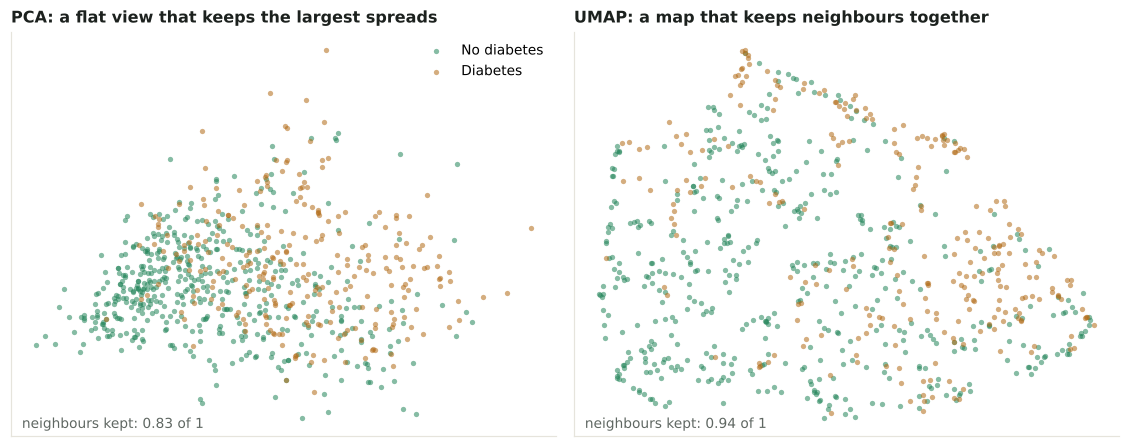

In [2]:
import json
from src import figures

m9 = json.load(open("../reports/metrics.json"))["m9"]
figures.m9_maps();
ex = m9["pca"]["explained"]
display(pd.Series({"first direction": f"{ex[0]:.0%}", "first two": f"{sum(ex[:2]):.0%}", "first three": f"{sum(ex[:3]):.0%}"},
                  name="share of the total spread kept"))
pd.DataFrame(m9["pca"]["loadings"]).round(2)

**How to read it.** Each dot is one woman. The left map (PCA) turns the six inputs into the two directions along which women differ most. The right map (UMAP) instead places women who are alike close together. Colour was added afterwards and was not used to draw either map. "Neighbours kept" scores how well each map keeps a woman's nearest neighbours near her (1 is perfect). The table says what each PCA direction is made of.

**What it means.** One cloud, not islands. Colour does sort left to right on the PCA map, and more loosely on UMAP: women without diabetes gather at the left and those with it toward the right, but the two overlap through the whole middle. The first PCA direction (mostly age, pregnancies and blood pressure) keeps only 33% of the spread and the first two keep 54%, so six inputs really are six separate things. UMAP keeps neighbours better (0.94 against 0.83) and draws some filaments, but a filament on a map is not proof of a group.

**What's next and why.** Ask a harder question: does a clustering method find groups that are real, or does it carve up a blob?

## 11.2 Are there natural groups?

**What we're looking for.** Whether splitting the women into 2 to 8 groups gives groups that are clearly separate and that reappear when the data is resampled.

,separation,separation with no groups (typical),... 95th percentile,stability,"mixture fit (BIC, lower is better)"
groups,,,,,
2,0.227,0.186,0.197,0.753,"12,003.946"
3,0.207,0.157,0.164,0.762,"12,025.668"
4,0.190,0.141,0.147,0.698,"11,950.178"
5,0.185,0.139,0.148,0.579,"12,077.494"
6,0.182,0.136,0.144,0.515,"12,168.306"
7,0.181,0.133,0.139,0.476,"12,276.959"
8,0.154,0.131,0.135,0.489,"12,429.197"


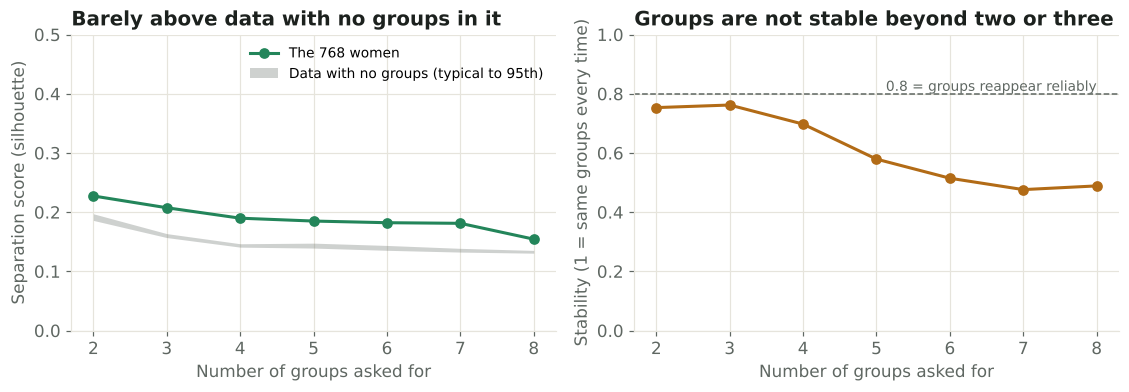

In [3]:
figures.m9_clusters();
scan = pd.DataFrame(m9["scan"]).T[["silhouette", "null_mean", "null_high", "stability", "bic"]]
scan.index.name = "groups"
scan.columns = ["separation", "separation with no groups (typical)", "... 95th percentile", "stability", "mixture fit (BIC, lower is better)"]
scan

**How to read it.** For each number of groups, k-means (a method that gathers women around group centres) splits the women. Separation (the silhouette score) is 1 for tight, well-apart groups and near 0 where they overlap. The grey band is the same score on 30 made-up datasets with the same averages and correlations but no groups in them, so it shows what a blob scores. Stability redraws the women twice, clusters each draw, and checks whether the two sets of groups agree (1 is identical every time). The last column is a second method's opinion.

**What it means.** The real data scores a little above the blob (0.23 against 0.19 for two groups) but the gap is small, and no score is high. Stability tops out at 0.76, under the 0.8 we would want, and drops to about 0.5 by six groups. The second method prefers four groups, which the stability check does not support (0.70). The honest reading is: a gentle bend, not distinct patient types. Any split is a convenience, not a discovery.

**What's next and why.** Even so, the best simple split might describe something useful. What do the groups look like?

## 11.3 What would the groups be?

**What we're looking for.** Whether the groups, taken at face value, describe patients we could name, and how diabetes varies between them.

In [4]:
for k in ["2", "3"]:
    prof = pd.DataFrame(m9["profiles"][k]).drop(columns="cluster")
    prof["diabetes_rate"] = prof["diabetes_rate"].map(lambda v: f"{v:.0%}")
    print(f"{k} groups")
    display(prof.rename(columns={"women": "women", "diabetes_rate": "with diabetes"}).round(2))

2 groups


,women,with diabetes,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
0,419,18%,2.000,106.000,66.000,30.000,0.350,25.000
1,349,55%,6.000,136.000,78.000,34.200,0.400,41.000


3 groups


,women,with diabetes,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
0,343,14%,2.000,103.000,64.000,28.500,0.330,25.000
1,234,54%,8.000,132.000,76.000,32.800,0.380,45.000
2,191,49%,1.000,134.500,80.000,37.750,0.460,28.000


**How to read it.** Each row is one group: how many women, the middle (median) value of each input, and the share with diabetes. The diabetes share was not used to make the groups.

**What it means.** Two groups: 419 younger women (median age 25, glucose 106, 18% with diabetes) and 349 older ones (age 41, glucose 136, 55%). Three groups split off a second type of young woman with high BMI (37.8) and high glucose (134), 49% with diabetes, in addition to a group of older women with many pregnancies (median 8, 54%). So the groups mostly re-describe what we already know: older, heavier, higher-glucose women are more likely to have diabetes. They are slices along one axis of risk, not separate kinds of patient.

**What's next and why.** The practical test: does knowing a woman's group help the model?

## 11.4 Do groups or oddness scores help the model?

**What we're looking for.** Whether adding cluster membership, distance to each group centre, or an oddness score as extra inputs improves the published model.

In [5]:
ft = m9["feature_test"]
rows = {"published model (no extras)": {"AUC": ft["base_auc"], "change": "", "95% range": "", "p": ""}}
names = {"member": "plus group membership (3 groups)", "distance": "plus distance to each group centre",
         "anomaly": "plus an oddness score"}
for key, label in names.items():
    r = ft[key]
    rows[label] = {"AUC": r["auc"], "change": f"{r['diff']:+.4f}", "95% range": f"{r['low']:+.4f} to {r['high']:+.4f}", "p": f"{r['p']:.2f}"}
pd.DataFrame(rows).T

,AUC,change,95% range,p
published model (no extras),0.853,,,
plus group membership (3 groups),0.852,-0.0017,-0.0052 to +0.0018,0.34
plus distance to each group centre,0.851,-0.0021,-0.0057 to +0.0015,0.24
plus an oddness score,0.852,-0.0008,-0.0021 to +0.0004,0.17


**How to read it.** This repeats the fair test from notebook 02: the same 50 splits, with the groups (or oddness scores) found inside each split on training women only, so the test women never influence them. Change is the difference in AUC against the published model, with the same corrected-for-overlap range and p-value used in the model contest.

**What it means.** None helps. All three are slightly worse than the published model (changes of -0.002, -0.002 and -0.001) and every range includes zero, so these are no real difference either way. The model already uses glucose, age, BMI and the rest directly, so a group label made from the same numbers has nothing new to say. For E23 the answer is: no new feature.

**What's next and why.** Switch from groups to individual odd records, the data-quality question (E24).

## 11.5 Which records are unusual?

**What we're looking for.** Whether three different oddness measures agree, and whether the readings we already suspect (insulin 846, skinfold 99) are found.

In [6]:
display(pd.Series(m9["agreement"]).to_frame("rank agreement (1 = identical order)").round(2))
rules = m9["rules"]
display(pd.Series({"insulin over 600": rules["insulin_over_600"], "skinfold over 60 mm": rules["skin_over_60"],
                   "BMI over 60": rules["bmi_over_60"], "more than 14 pregnancies": rules["pregnancies_over_14"],
                   "blood pressure under 40": rules["bp_under_40"], "glucose under 50": rules["glucose_under_50"]}).to_frame("women"))
chk = pd.DataFrame({"six model inputs": {k: v["rank_of_768"] for k, v in m9["six_inputs"].items()},
                    "all eight columns": {k: v["rank_of_768"] for k, v in m9["eight_inputs"].items()}})
chk.index = ["insulin 846", "skinfold 99", "BMI 67.1", "17 pregnancies", "blood pressure 24"]
display(chk.rename_axis("where the known extreme ranks (1 = most unusual of 768)"))

,rank agreement (1 = identical order)
isolation_lof,0.810
isolation_mahalanobis,0.950
lof_mahalanobis,0.810


,women
insulin over 600,3
skinfold over 60 mm,2
BMI over 60,1
more than 14 pregnancies,2
blood pressure under 40,4
glucose under 50,1


,six model inputs,all eight columns
where the known extreme ranks (1 = most unusual of 768),,
insulin 846,23.500,4.000
skinfold 99,45.500,3.000
BMI 67.1,13.000,8.000
17 pregnancies,82.500,26.000
blood pressure 24,165.000,29.000


**How to read it.** Three methods score oddness: isolation forest (how few cuts it takes to isolate a woman), local outlier factor (is she far from her nearest neighbours) and Mahalanobis distance (how far from the average, allowing for how inputs move together). The first table shows how closely their orderings agree. The second counts readings that break plain rules of thumb. The third ranks the extremes we already know about, first using only the six inputs the model uses, then all eight columns.

**What it means.** The measures mostly agree (0.81 to 0.95). On the six model inputs the extremes rank 13th (BMI 67) to 165th (blood pressure 24) of 768, because insulin and skinfold are not among the six and count for nothing there. With all eight columns, skinfold 99 ranks 3rd, insulin 846 4th and BMI 67 8th, so the detectors do find the readings a person would flag. A handful of rule breaks (three insulin readings over 600, two skinfolds over 60, four blood pressures under 40) are few enough to check by hand. Those are the candidates for data errors.

**What's next and why.** Look at the most unusual women on the model's own inputs.

## 11.6 The most unusual women

**What we're looking for.** What makes the top of the list unusual, and whether any look like mistakes.

In [7]:
odd = pd.DataFrame(m9["odd_records"]).head(10)
odd = odd[["row", "most_unusual_value", "value", "Pregnancies", "Glucose", "BloodPressure", "BMI", "DiabetesPedigreeFunction", "Age"]]
odd.columns = ["row", "most unusual input", "its value", "pregnancies", "glucose", "blood pressure", "BMI", "family history", "age"]
odd.set_index("row")

,most unusual input,its value,pregnancies,glucose,blood pressure,BMI,family history,age
row,,,,,,,,
537,Age,67.000,0.000,57.000,60.000,21.700,0.735,67.000
4,DiabetesPedigreeFunction,2.288,0.000,137.000,40.000,43.100,2.288,33.000
294,Age,65.000,0.000,161.000,50.000,21.900,0.254,65.000
445,DiabetesPedigreeFunction,2.420,0.000,180.000,78.000,59.400,2.420,25.000
125,BloodPressure,30.000,1.000,88.000,30.000,55.000,0.496,26.000
487,Age,58.000,0.000,173.000,78.000,46.500,1.159,58.000
593,DiabetesPedigreeFunction,1.699,2.000,82.000,52.000,28.500,1.699,25.000
362,BloodPressure,108.000,5.000,103.000,108.000,39.200,0.305,65.000
45,DiabetesPedigreeFunction,1.893,0.000,180.000,66.000,42.000,1.893,25.000


**How to read it.** Each row is one woman, ranked by the average of the three methods. "Most unusual input" is the input furthest from the average in standard deviations, with its value in the next column.

**What it means.** Most are rare rather than wrong: women of 65 or 67, or with a very high family-history score (2.3 to 2.4 against a typical 0.37). A few deserve doubt: blood pressure 30 (row 125) is hard to believe in a living woman measured at rest, and BMI 67.1 with blood pressure 110 (row 177, further down the list) is possible but extreme. We cannot verify any of them against the original charts, so we only record them. Nothing here is clearly an error the model should be protected from.

**What's next and why.** Do these women get worse predictions, and does removing them help?

## 11.7 Do unusual women get worse predictions? Does removing them help?

**What we're looking for.** Whether the model is less accurate for the most unusual 5% of women, and whether dropping the most unusual 2% from training improves it.

In [8]:
ec = pd.DataFrame(m9["error_check"]).T
ec = ec[["n_odd", "mean_error_odd", "mean_error_rest", "auc_odd", "auc_rest", "spearman_error_vs_oddness"]]
ec.columns = ["women in top 5%", "average miss, unusual", "average miss, others", "AUC, unusual", "AUC, others", "link between oddness and miss"]
display(ec)
tt = m9["trim_test"]
pd.Series({"AUC with all 768 women in training": round(tt["auc_all"], 4),
           f"AUC without the {m9['n_removed']} most unusual": round(tt["auc_trimmed"], 4),
           "change": f"{tt['diff']:+.4f}", "95% range": f"{tt['low']:+.4f} to {tt['high']:+.4f}", "p": round(tt["p"], 2)}).to_frame("result")

,women in top 5%,"average miss, unusual","average miss, others","AUC, unusual","AUC, others",link between oddness and miss
isolation,39.000,0.340,0.290,0.737,0.857,0.007
lof,39.000,0.281,0.293,0.858,0.854,0.051
mahalanobis,39.000,0.346,0.289,0.736,0.860,-0.008


,result
AUC with all 768 women in training,0.853
AUC without the 15 most unusual,0.853
change,-0.0001
95% range,-0.0026 to +0.0023
p,0.910


**How to read it.** Average miss is how far the out-of-sample risk is from the woman's true outcome (0 or 1), averaged. AUC is the ranking measure used throughout; here it is computed within each subgroup. The last column is a rank correlation (0 means no link) between oddness and miss across all 768 women. The second table is the same fair test as before, comparing training with and without the most unusual women.

**What it means.** Mixed and weak. Two of the three methods show the unusual 5% (39 women) scored a little worse (average miss 0.34 against 0.29) and ranked less well (AUC 0.74 against 0.86). But 39 women is a small group, the third method sees no difference, and across all 768 women the link between oddness and error is near zero (-0.01 to 0.05). Removing the 15 most unusual from training changes AUC by -0.0001 (range -0.003 to +0.002). The model neither needs nor benefits from cleaning them out. For E24 the conclusion is: record them, keep them.

**What's next and why.** One more use of oddness, a warning on the page. Does it flag women the model is unsure about?

## 11.8 A warning: does she look like the women the model learned from?

**What we're looking for.** Whether a woman who is far from the typical Pima woman is treated worse, and whether it would have flagged the outside women of notebook 10.

,NHANES women,with diabetes,average predicted,share with diabetes,AUC
unusual (beyond the 95th percentile),252.000,20.000,25.0%,7.9%,0.85
typical,709.000,17.000,25.3%,2.4%,0.91


,value
"typical distance, Pima women",2.140
"typical distance, NHANES women",2.800
NHANES women beyond the 95th percentile of Pima,26%
beyond the 99th,11%
"Pima: median width of 95% range, unusual women",28%
"Pima: median width of 95% range, others",19%


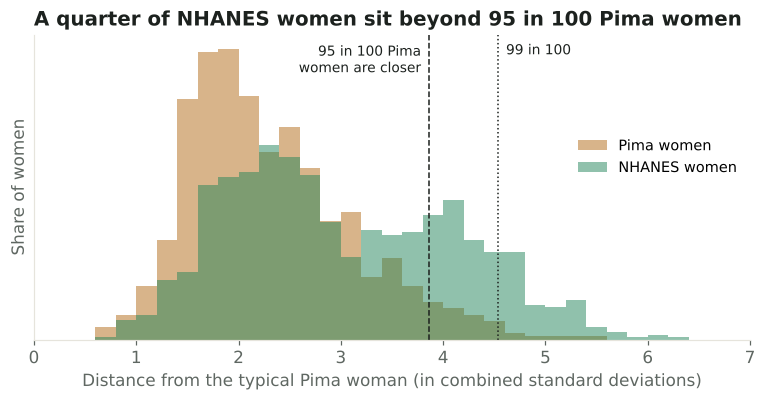

In [9]:
figures.m9_reach();
rc = m9["reach"]
g = pd.DataFrame({"unusual (beyond the 95th percentile)": rc["flagged"], "typical": rc["typical"]}).T
g["observed"] = g["observed"].map("{:.1%}".format)
g["mean_predicted"] = g["mean_predicted"].map("{:.1%}".format)
g["auc"] = g["auc"].map(lambda v: f"{v:.2f}")
display(g.rename(columns={"n": "NHANES women", "positives": "with diabetes", "mean_predicted": "average predicted",
                          "observed": "share with diabetes", "auc": "AUC"}))
pd.Series({"typical distance, Pima women": round(rc["median_pima"], 2), "typical distance, NHANES women": round(rc["median_nhanes"], 2),
           "NHANES women beyond the 95th percentile of Pima": f"{rc['nhanes_over_q95']:.0%}",
           "beyond the 99th": f"{rc['nhanes_over_q99']:.0%}",
           "Pima: median width of 95% range, unusual women": f"{rc['pima_over_q95_width']:.0%}",
           "Pima: median width of 95% range, others": f"{rc['pima_rest_width']:.0%}"}).to_frame("value")

**How to read it.** Distance measures how far a woman's six inputs are from the typical Pima woman, counting inputs that move together as one (Mahalanobis distance). The chart compares Pima and NHANES women. The table splits the NHANES women into those beyond what 95 in 100 Pima women look like and the rest. The last rows compare how wide the bootstrap range from notebook 09 is for unusual Pima women.

**What it means.** A quarter of NHANES women are beyond that line (26%, where 5% would be expected if they were like the Pima women), and 11% beyond the 99th. Inside the Pima data, unusual women have wider ranges (28 points against 19), so the model does know it is less sure of them. But the flag does not repair NHANES: predicted risk is about 25% in both subgroups while the true rates differ (8% and 2%), and the ranking is only a bit weaker for the unusual women (AUC 0.85 against 0.91). The risk level is wrong for everyone, as notebook 10 found. So the flag is an honest signal of "this woman is unlike the women I learned from", and the page shows it as that, not as a correction.

**What's next and why.** Decide what changes: a notice on the page, no change to the model.

## 11.9 What this changes

**What we're looking for.** Whether anything here alters the published model, and what goes on the page.

In [10]:
pd.Series({"Published model changed": "no",
           "E23 (clusters and maps)": "no clear groups; groups and distances do not improve AUC; report as 'nothing useful here'",
           "E24 (odd records)": "extremes are found by all three methods; rare, not harmful; keep them and record them",
           "New on the page": "a notice when a woman's inputs are unlike the Pima women (beyond the 95th percentile)",
           "Not claimed": "that unusual women are always mispredicted (the evidence is weak and the subgroup small)"}).to_frame("decision")

,decision
Published model changed,no
E23 (clusters and maps),no clear groups; groups and distances do not i...
E24 (odd records),"extremes are found by all three methods; rare,..."
New on the page,a notice when a woman's inputs are unlike the ...
Not claimed,that unusual women are always mispredicted (th...


**How to read it.** A summary of the decisions this notebook supports.

**What it means.** Hidden structure turned out to be mostly absent. The map shows a cloud, the groups are unstable, and the groups that do appear only restate age, weight and glucose. The odd-record search confirms that known extreme readings stand out, and that dropping them changes nothing measurable. The one visible product is the unusual-inputs notice. A negative result stated plainly, with the test that supports it, is as useful in a portfolio as a positive one.

**What's next and why.** Milestone 10 packages the project: a model card, automated tests on every push, and run tracking.